# Five qubits + four tunable couplers: first pass

**To change the design:** edit the numbers in the *Design parameters* cell, then **Restart & Run All**.

The cells after that build the chip from those numbers. The only hand-placed layout coordinates are in the feedline return path and the control-line routing table, and both say so in their comments.

The tunable coupler component lives in `h_coupler.py` next to this notebook.

In [1]:
import os

os.environ.setdefault("QISKIT_METAL_HEADLESS", "True")

from qiskit_metal import designs, Dict
import qiskit_metal as qm
from qiskit_metal.qlibrary.qubits.transmon_cross_fl import TransmonCrossFL
from qiskit_metal.qlibrary.couplers.coupled_line_tee import CoupledLineTee
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander
from qiskit_metal.qlibrary.terminations.launchpad_wb import LaunchpadWirebond
from qiskit_metal.qlibrary.terminations.open_to_ground import OpenToGround
from qiskit_metal.qlibrary.tlines.straight_path import RouteStraight
from qiskit_metal.qlibrary.tlines.anchored_path import RouteAnchors
from qiskit_metal.qlibrary.lumped.cap_n_interdigital import CapNInterdigital

from h_coupler import TransmonHCoupler  # local file: h_coupler.py

## Design parameters

In [2]:
# =====================================================================
#  DESIGN PARAMETERS
#  Every number you are likely to tune lives in this cell. Edit, then
#  Restart & Run All. The suffix on each name is its unit (_um / _mm).
# =====================================================================

# --- Chip ------------------------------------------------------------
chip_size_mm = 5.0
cpw_width_um = 10  # default centre trace for every route
cpw_gap_um = 6

# --- Qubits (TransmonCrossFL) -----------------------------------------
n_qubits = 5
qubit_pitch_mm = 0.65
qubit_row_y_mm = 0.0
cross_width_um = 30
cross_length_um = 190  # centre to arm tip
cross_gap_um = 50

# Readout claw on the north arm
claw_length_um = 40
claw_width_um = 10
claw_gap_um = 6
claw_ground_spacing_um = 5

# XY drive pad (open-ended CPW), placed relative to each qubit centre
xy_pad_dx_mm = -0.10
xy_pad_dy_mm = -0.18
xy_pad_width_um = 10
xy_pad_gap_um = 6
xy_pad_termination_gap_um = 6

# Flux-line T at the SQUID (used by both qubits and couplers)
flux_t_top_um = 15
flux_t_width_um = 5
flux_t_gap_um = 3
flux_t_inductive_gap_um = 3
flux_t_offset_um = 0

# --- Tunable couplers (TransmonHCoupler, see h_coupler.py) ------------
# One I-beam coupler midway between each qubit pair, on the qubit row.
# The neighbouring qubits' arm tips sit inside its two slots.
coupler_insertion_um = 50  # how far each qubit arm tip reaches into a slot
coupler_tip_gap_um = 30  # qubit arm tip to the coupler's central web
coupler_arm_clearance_um = 20  # qubit arm edge to each bar, above and below
coupler_bar_width_um = 30
coupler_pocket_gap_um = 30  # coupler metal to ground plane
coupler_jj_width_um = 20

# --- Readout --------------------------------------------------------------
resonator_lengths_mm = [4.41, 4.45, 4.49, 4.53, 4.57]  # quarter-wave, Q0..Q4
resonator_meander_spacing_um = 50
resonator_lead_um = 150  # straight section at each end of the meander
resonator_fillet_um = 20

feedline_y_mm = 1.5
tee_coupling_length_um = 200
tee_coupling_space_um = 4

# Purcell-filter section of the feedline (cap to cap, incl. tee couplers).
# The return run's fold-back is placed automatically to hit this length.
purcell_length_mm = 9.028

# --- Launchpads -------------------------------------------------------
pad_inset_mm = 2.2  # pad centre distance from chip centre
ns_pad_offsets_mm = [-1.625, -0.975, -0.325, 0.325, 0.975, 1.625]  # N & S edges
ew_pad_offsets_mm = [-1.6, -0.6, 0.4, 1.4]  # E & W edges

# --- Routing --------------------------------------------------------
control_line_fillet_um = 50
feedline_fillet_um = 50

## Qubits and tunable couplers

In [3]:
design = designs.DesignPlanar()
design.chips.main.size.size_x = f"{chip_size_mm}mm"
design.chips.main.size.size_y = f"{chip_size_mm}mm"
design.variables.cpw_width = f"{cpw_width_um}um"
design.variables.cpw_gap = f"{cpw_gap_um}um"
design.overwrite_enabled = True

flux_t_options = dict(
    t_top=f"{flux_t_top_um}um",
    t_width=f"{flux_t_width_um}um",
    t_gap=f"{flux_t_gap_um}um",
    t_inductive_gap=f"{flux_t_inductive_gap_um}um",
    t_offset=f"{flux_t_offset_um}um",
)


def qubit_x(i):
    """x position (mm) of qubit i, centred on the chip."""
    return (i - (n_qubits - 1) / 2) * qubit_pitch_mm


qubits, xy_pads = [], []
for i in range(n_qubits):
    x_pos = qubit_x(i)
    qubits.append(
        TransmonCrossFL(
            design,
            f"Q{i}",
            options=dict(
                pos_x=f"{x_pos}mm",
                pos_y=f"{qubit_row_y_mm}mm",
                orientation="0",
                cross_width=f"{cross_width_um}um",
                cross_length=f"{cross_length_um}um",
                cross_gap=f"{cross_gap_um}um",
                make_fl=True,
                fl_options=flux_t_options,
                connection_pads=dict(
                    readout=dict(
                        connector_type="0",
                        claw_length=f"{claw_length_um}um",
                        ground_spacing=f"{claw_ground_spacing_um}um",
                        claw_width=f"{claw_width_um}um",
                        claw_gap=f"{claw_gap_um}um",
                        connector_location="90",
                    )
                ),
            ),
        )
    )
    xy_pads.append(
        OpenToGround(
            design,
            f"XY_pad_{i}",
            options=dict(
                pos_x=f"{x_pos + xy_pad_dx_mm}mm",
                pos_y=f"{qubit_row_y_mm + xy_pad_dy_mm}mm",
                orientation="90",
                width=f"{xy_pad_width_um}um",
                gap=f"{xy_pad_gap_um}um",
                termination_gap=f"{xy_pad_termination_gap_um}um",
            ),
        )
    )

print(f"Design initialized on a {chip_size_mm} x {chip_size_mm} mm chip.")
print(f"Placed qubits Q0-Q{n_qubits - 1} and their XY coupling pads.")

06:39PM 48s INFO [_start_renderers]: Renderer=hfss skipped: runtime dependency not installed (QAnsysRenderer requires pyEPR. Install with: pip install 'quantum-metal[ansys]').
06:39PM 48s INFO [_start_renderers]: Renderer=q3d skipped: runtime dependency not installed (QAnsysRenderer requires pyEPR. Install with: pip install 'quantum-metal[ansys]').
06:39PM 48s INFO [_start_renderers]: Renderer=gmsh skipped: runtime dependency not installed (renderer_gmsh requires gmsh. Install with: pip install 'quantum-metal[mesh]' (or the legacy alias 'quantum-metal[fem]')).
06:39PM 48s INFO [_start_renderers]: Renderer=aedt_q3d skipped: runtime dependency not installed (QPyaedt requires pyaedt (ansys.aedt.core). Install with: pip install 'quantum-metal[ansys]').
06:39PM 48s INFO [_start_renderers]: Renderer=aedt_hfss skipped: runtime dependency not installed (QPyaedt requires pyaedt (ansys.aedt.core). Install with: pip install 'quantum-metal[ansys]').


Design initialized on a 5.0 x 5.0 mm chip.
Placed qubits Q0-Q4 and their XY coupling pads.


In [4]:
# Coupler geometry follows from the qubit geometry and the three coupling
# knobs (insertion, tip gap, arm clearance), so changing the qubit pitch or
# arm length keeps the arm tips centred in the slots.
tip_from_coupler_um = qubit_pitch_mm * 1e3 / 2 - cross_length_um
coupler_bar_length_um = 2 * (tip_from_coupler_um + coupler_insertion_um)
coupler_web_width_um = 2 * (tip_from_coupler_um - coupler_tip_gap_um)
coupler_slot_height_um = cross_width_um + 2 * coupler_arm_clearance_um
assert coupler_web_width_um > 0, (
    "coupler_tip_gap_um is larger than the space between the arm tip and the "
    f"coupler centre ({tip_from_coupler_um:.0f} um)"
)

tunable_couplers = []
for i in range(n_qubits - 1):
    tunable_couplers.append(
        TransmonHCoupler(
            design,
            f"TC{i}",
            options=dict(
                pos_x=f"{(qubit_x(i) + qubit_x(i + 1)) / 2}mm",
                pos_y=f"{qubit_row_y_mm}mm",
                orientation="0",
                bar_length=f"{coupler_bar_length_um}um",
                bar_width=f"{coupler_bar_width_um}um",
                slot_height=f"{coupler_slot_height_um}um",
                web_width=f"{coupler_web_width_um}um",
                pocket_gap=f"{coupler_pocket_gap_um}um",
                jj_width=f"{coupler_jj_width_um}um",
                make_fl=True,
                fl_options=flux_t_options,
            ),
        )
    )

print(f"Placed tunable couplers TC0-TC{n_qubits - 2} between the qubits.")
print(
    f"  coupler bars {coupler_bar_length_um:.0f} um long, web "
    f"{coupler_web_width_um:.0f} um, slot {coupler_slot_height_um:.0f} um tall"
)

Placed tunable couplers TC0-TC3 between the qubits.
  coupler bars 370 um long, web 210 um, slot 70 um tall


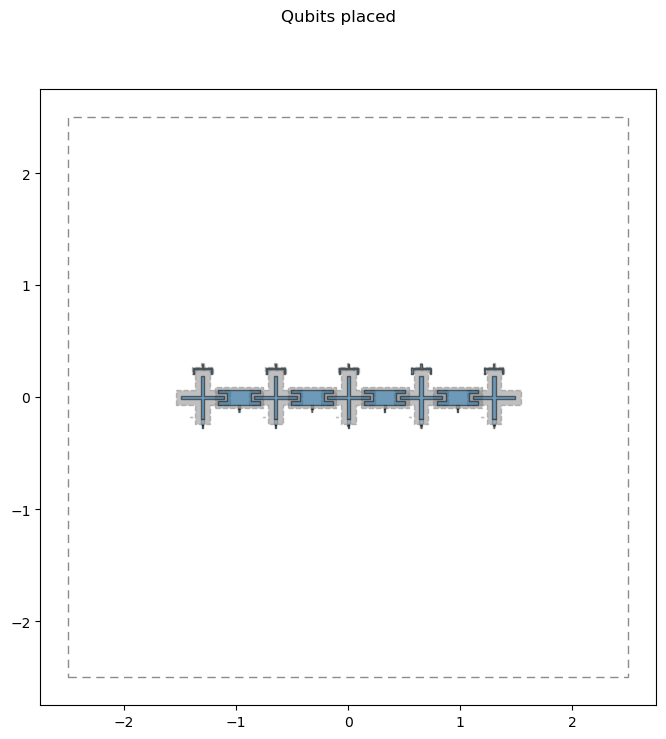

In [5]:
fig = qm.view(design)
fig.suptitle("Qubits placed")
fig

## Readout and feedline

In [6]:
readout_tees = []
for i in range(n_qubits):
    readout_tees.append(
        CoupledLineTee(
            design,
            f"CLT{i}",
            options=dict(
                pos_x=f"{qubit_x(i)}mm",
                pos_y=f"{feedline_y_mm}mm",
                orientation="0",
                coupling_length=f"{tee_coupling_length_um}um",
                coupling_space=f"{tee_coupling_space_um}um",
                # Short the resonator end to ground: with the open claw at
                # the qubit, each readout resonator is a quarter-wave.
                open_termination=False,
            ),
        )
    )

# Wirebond launchpads. Numbered west->east (N/S edges), south->north (E/W).
pad_edges = {
    "W": (ew_pad_offsets_mm, lambda p: (-pad_inset_mm, p, "0")),
    "E": (ew_pad_offsets_mm, lambda p: (pad_inset_mm, p, "180")),
    "S": (ns_pad_offsets_mm, lambda p: (p, -pad_inset_mm, "90")),
    "N": (ns_pad_offsets_mm, lambda p: (p, pad_inset_mm, "270")),
}
for edge, (offsets, place) in pad_edges.items():
    for n, offset in enumerate(offsets, start=1):
        x, y, orient = place(offset)
        LaunchpadWirebond(
            design,
            f"LP_{edge}{n}",
            options=dict(pos_x=f"{x}mm", pos_y=f"{y}mm", orientation=orient),
        )

# Feedline caps stand vertically under N1 (in) and N6 (out)
cap_in = CapNInterdigital(
    design,
    "Cap_input",
    options=dict(pos_x=f"{ns_pad_offsets_mm[0]}mm", pos_y="1.75mm", orientation="180"),
)
cap_out = CapNInterdigital(
    design,
    "Cap_output",
    options=dict(pos_x=f"{ns_pad_offsets_mm[-1]}mm", pos_y="2.125mm", orientation="0"),
)

print("Placed launchpads and feedline terminations.")

Placed launchpads and feedline terminations.


In [7]:
RouteStraight(
    design,
    "Feed_in_lp",
    options=dict(
        pin_inputs=dict(
            start_pin=dict(component="LP_N1", pin="tie"),
            end_pin=dict(component="Cap_input", pin="south_end"),
        )
    ),
)

feed_in_clt = RouteAnchors(
    design,
    "Feed_in_clt",
    options=dict(
        pin_inputs=dict(
            start_pin=dict(component="Cap_input", pin="north_end"),
            end_pin=dict(component="CLT0", pin="prime_start"),
        ),
        anchors=Dict({0: (ns_pad_offsets_mm[0], feedline_y_mm)}),
        fillet=f"{feedline_fillet_um}um",
        advanced=Dict(avoid_collision=False),
    ),
)

feed_mids = [
    RouteStraight(
        design,
        f"Feed_mid_{i}",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"CLT{i}", pin="prime_end"),
                end_pin=dict(component=f"CLT{i + 1}", pin="prime_start"),
            )
        ),
    )
    for i in range(n_qubits - 1)
]

# Return run: east past CLT4, back west above the tees, then east again
# under the north pads into Cap_output. Its fold-back x sets the Purcell
# length; it is solved for below so the section hits purcell_length_mm.
return_low_y, return_high_y = feedline_y_mm + 0.2, feedline_y_mm + 0.4


def route_return(fold_x):
    return RouteAnchors(
        design,
        "Feed_out_clt",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"CLT{n_qubits - 1}", pin="prime_end"),
                end_pin=dict(component="Cap_output", pin="south_end"),
            ),
            anchors=Dict(
                {
                    0: (1.6, feedline_y_mm),
                    1: (1.6, return_low_y),
                    2: (fold_x, return_low_y),
                    3: (fold_x, return_high_y),
                    4: (ns_pad_offsets_mm[-1], return_high_y),
                }
            ),
            fillet=f"{feedline_fillet_um}um",
            advanced=Dict(avoid_collision=False),
        ),
    )


def purcell_length(feed_return):
    return (
        n_qubits * tee_coupling_length_um / 1e3
        + feed_in_clt.length
        + sum(f.length for f in feed_mids)
        + feed_return.length
    )


purcell_fold_x = -1.4  # initial guess; length grows 2 mm per mm moved west
for _ in range(3):
    feed_return = route_return(purcell_fold_x)
    purcell_fold_x -= (purcell_length_mm - purcell_length(feed_return)) / 2
feed_return = route_return(purcell_fold_x)

min_fold_x = ns_pad_offsets_mm[0] + 0.1  # keep clear of the input feed
assert purcell_fold_x >= min_fold_x, (
    f"purcell_length_mm = {purcell_length_mm} needs the fold-back at "
    f"x = {purcell_fold_x:.3f} mm, past the input feed (limit {min_fold_x:.3f} mm). "
    "A longer Purcell section needs a different return path."
)

RouteStraight(
    design,
    "Feed_out_lp",
    options=dict(
        pin_inputs=dict(
            start_pin=dict(component="Cap_output", pin="north_end"),
            end_pin=dict(component="LP_N6", pin="tie"),
        )
    ),
)

print("Feedline routed.")
print(
    f"Purcell-filter feedline length: {purcell_length(feed_return):.3f} mm "
    f"(fold-back at x = {purcell_fold_x:.3f} mm)"
)

Feedline routed.
Purcell-filter feedline length: 9.028 mm (fold-back at x = -1.489 mm)


In [8]:
for i in range(n_qubits):
    RouteMeander(
        design,
        f"ReadoutRes{i}",
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=f"Q{i}", pin="readout"),
                end_pin=dict(component=f"CLT{i}", pin="second_end"),
            ),
            total_length=f"{resonator_lengths_mm[i]}mm",
            fillet=f"{resonator_fillet_um}um",
            lead=dict(
                start_straight=f"{resonator_lead_um}um",
                end_straight=f"{resonator_lead_um}um",
            ),
            meander=dict(spacing=f"{resonator_meander_spacing_um}um", asymmetry="0um"),
        ),
    )

print("Staggered meander resonators routed.")

06:39PM 49s WARNING [check_lengths]: For path table, component=ReadoutRes0, key=trace has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
06:39PM 49s WARNING [check_lengths]: For path table, component=ReadoutRes0, key=cut has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
06:39PM 49s WARNING [check_lengths]: For path table, component=ReadoutRes1, key=trace has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
06:39PM 49s WARNING [check_lengths]: For path table, component=ReadoutRes1, key=cut has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
06:39PM 49s WARNING [check_lengths]: For path table, component=ReadoutRes2, key=trace has short segments that could cause issues with fillet. Values in (29-30)  are index(es) in shapely geometry.
06:39PM 49s WARNING [che

Staggered meander resonators routed.


## Control lines

In [9]:
# Control lines: every XY / flux line leaves the qubit row heading south, so
# the launchpads are assigned in perimeter order (W4 -> W1 -> S1..S6 ->
# E1..E4) to keep the routes nested and crossing-free.
#
# Each line drops from its start pin to `depth`, then:
#   - to a N/S pad: runs across to the pad's x and drops into it
#   - to an E/W pad: runs out to `column`, then up/down to the pad's y.
#     With column=None it runs straight out at the pad's own y (depth unused).
# Lines that turn off shallower get the inner columns. Coordinates in mm.
control_lines = [
    # (name,                  start,      pin,         pad,     depth, column)
    ("XY_line_0",             "XY_pad_0", "open",      "LP_W4", -0.30, -1.85),
    ("Flux_line_0",           "Q0",       "flux_line", "LP_W3", -0.45, -2.00),
    ("Coupler_flux_line_0",   "TC0",      "flux_line", "LP_W2", None,  None),
    ("XY_line_1",             "XY_pad_1", "open",      "LP_W1", None,  None),
    ("Flux_line_1",           "Q1",       "flux_line", "LP_S1", -1.75, None),
    ("Coupler_flux_line_1",   "TC1",      "flux_line", "LP_S2", -1.90, None),
    ("XY_line_2",             "XY_pad_2", "open",      "LP_S3", -2.05, None),
    ("Flux_line_2",           "Q2",       "flux_line", "LP_S4", -2.05, None),
    ("Coupler_flux_line_2",   "TC2",      "flux_line", "LP_S5", -1.90, None),
    ("XY_line_3",             "XY_pad_3", "open",      "LP_S6", -1.75, None),
    ("Flux_line_3",           "Q3",       "flux_line", "LP_E1", None,  None),
    ("Coupler_flux_line_3",   "TC3",      "flux_line", "LP_E2", -0.75, 2.05),
    ("XY_line_4",             "XY_pad_4", "open",      "LP_E3", -0.60, 1.90),
    ("Flux_line_4",           "Q4",       "flux_line", "LP_E4", -0.45, 1.75),
]


def control_corners(start, pin, pad, depth, column):
    """Corner points for one control line, from the pin and pad positions."""
    x0, _ = design.components[start].pins[pin].middle
    px, py = design.components[pad].pins["tie"].middle
    if pad[3] in "NS":
        return [(x0, depth)] + ([(px, depth)] if abs(px - x0) > 1e-6 else [])
    if column is None:
        return [(x0, py)]
    return [(x0, depth), (column, depth), (column, py)]


for name, start, pin, pad, depth, column in control_lines:
    RouteAnchors(
        design,
        name,
        options=dict(
            pin_inputs=dict(
                start_pin=dict(component=start, pin=pin),
                end_pin=dict(component=pad, pin="tie"),
            ),
            anchors=Dict(dict(enumerate(control_corners(start, pin, pad, depth, column)))),
            fillet=f"{control_line_fillet_um}um",
            advanced=Dict(avoid_collision=False),
        ),
    )

print("XY drive and flux lines routed to launchpads.")

XY drive and flux lines routed to launchpads.


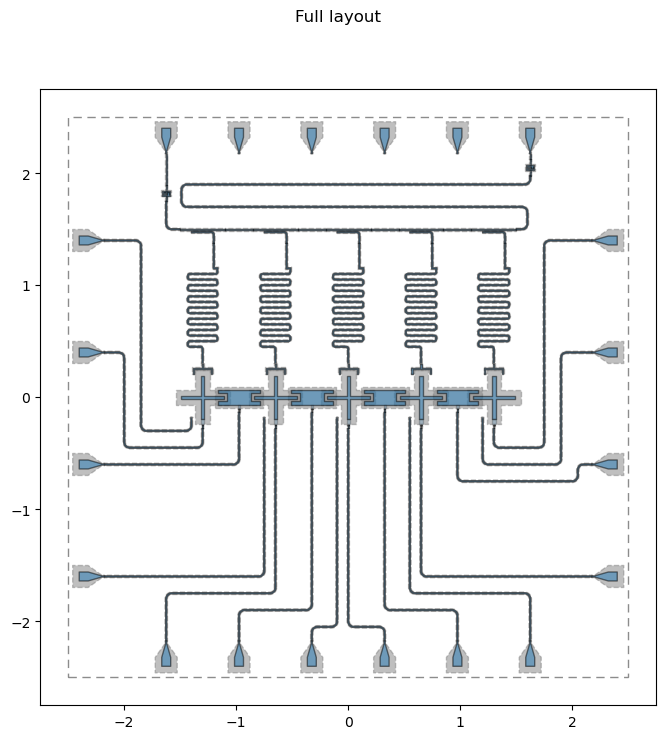

In [10]:
fig = qm.view(design)
fig.suptitle("Full layout")
fig